In [ ]:
# ╔══════════════════════════════════════════════════════════╗
# ║   TUFTS DENTAL DATASET — PROPER EXPLORATION              ║
# ║   Run cells top to bottom                                ║
# ╚══════════════════════════════════════════════════════════╝

# ── CELL 1: Mount + paths ─────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')

import os
from pathlib import Path

BASE = "/content/drive/MyDrive/Capstone/tufts/ZIP"   # ← adjust if needed

# All key paths
RADIO_DIR   = f"{BASE}/Radiographs/Radiographs"
SEG_DIR     = f"{BASE}/Segmentation/Segmentation"
MAXILLO_DIR = f"{SEG_DIR}/maxillomandibular"
TEETH_DIR   = f"{SEG_DIR}/teeth_mask"
BBOX_JSON   = f"{SEG_DIR}/teeth_bbox.json"
POLY_JSON   = f"{SEG_DIR}/teeth_polygon.json"
EXPERT_DIR  = f"{BASE}/Expert/Expert"
EXPERT_JSON = f"{EXPERT_DIR}/expert.json"
EXPERT_MASK = f"{EXPERT_DIR}/mask"
EXPERT_GAZE = f"{EXPERT_DIR}/gaze_map/gray"
STUDENT_DIR = f"{BASE}/Student/Student"
STUDENT_JSON= f"{STUDENT_DIR}/student.json"

# Quick existence check
for label, path in [
    ("Radiographs",      RADIO_DIR),
    ("Maxillomandibular",MAXILLO_DIR),
    ("Teeth masks",      TEETH_DIR),
    ("Bbox JSON",        BBOX_JSON),
    ("Polygon JSON",     POLY_JSON),
    ("Expert JSON",      EXPERT_JSON),
    ("Expert mask",      EXPERT_MASK),
]:
    exists = os.path.exists(path)
    count  = len(os.listdir(path)) if exists and os.path.isdir(path) else "—"
    print(f"  {'✅' if exists else '❌'}  {label:20s}  {count}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  ✅  Radiographs           1000
  ✅  Maxillomandibular     1000
  ✅  Teeth masks           308
  ✅  Bbox JSON             —
  ✅  Polygon JSON          —
  ✅  Expert JSON           —
  ✅  Expert mask           439


In [ ]:
# ── CELL 2: Installs ──────────────────────────────────────
!pip install -q fpdf2
!apt-get install -qq fonts-dejavu-core

import shutil
shutil.copy("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
            "/content/DejaVuSans.ttf")
shutil.copy("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
            "/content/DejaVuSans-Bold.ttf")
print("✅ Ready")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.0/81.0 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.1/327.1 kB 33.9 MB/s eta 0:00:00
Selecting previously unselected package fonts-dejavu-core.
(Reading database ... 122354 files and directories currently installed.)
Preparing to unpack .../fonts-dejavu-core_2.37-2build1_all.deb ...
Unpacking fonts-dejavu-core (2.37-2build1) ...
Setting up fonts-dejavu-core (2.37-2build1) ...
Processing triggers for fontconfig (2.13.1-4.2ubuntu5) ...
✅ Ready


In [ ]:
# ── CELL 3: Imports ───────────────────────────────────────
import json, re, cv2, random, datetime, shutil, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path
from collections import Counter, defaultdict
from PIL import Image as PILImage
PILImage.MAX_IMAGE_PIXELS = None

report_data = {}   # accumulates all findings for PDF
figures     = {}   # name → save path

random.seed(42)
print("✅ Imports done")

✅ Imports done


In [ ]:
# ── CELL 4: File inventory ────────────────────────────────
def count_dir(d):
    if not os.path.exists(d): return 0
    return len([f for f in os.listdir(d)
                if os.path.isfile(os.path.join(d, f))])

inventory = {
    "Radiographs"       : count_dir(RADIO_DIR),
    "Maxillomandibular" : count_dir(MAXILLO_DIR),
    "Teeth masks"       : count_dir(TEETH_DIR),
    "Expert masks"      : count_dir(EXPERT_MASK),
    "Expert gaze"       : count_dir(EXPERT_GAZE),
    "Student gaze"      : count_dir(f"{STUDENT_DIR}/gaze_map/gray"),
}

print("=" * 45)
print("  FILE INVENTORY")
print("=" * 45)
for k, v in inventory.items():
    print(f"  {k:22s}: {v:4d} files")

report_data['inventory'] = inventory

# Radiograph file list (ground truth set)
radio_files = sorted([
    os.path.join(RADIO_DIR, f)
    for f in os.listdir(RADIO_DIR)
    if Path(f).suffix.lower() in {'.jpg','.jpeg','.png'}
])
radio_ids = [Path(f).stem for f in radio_files]
print(f"\n  Total radiograph IDs: {len(radio_ids)}")
print(f"  Sample IDs: {radio_ids[:8]}")
report_data['total_radiographs'] = len(radio_ids)

  FILE INVENTORY
  Radiographs           : 1000 files
  Maxillomandibular     : 1000 files
  Teeth masks           :  308 files
  Expert masks          :  439 files
  Expert gaze           : 1000 files
  Student gaze          :  941 files

  Total radiograph IDs: 1000
  Sample IDs: ['1', '100', '1000', '1001', '1002', '1004', '1007', '1008']


In [ ]:
# ── CELL 5: Parse expert.json ─────────────────────────────
with open(EXPERT_JSON) as f:
    expert_raw = json.load(f)

print("Type:", type(expert_raw))
if isinstance(expert_raw, dict):
    print("Keys:", list(expert_raw.keys()))
    # show first record fully
    first_key = list(expert_raw.keys())[0]
    print(f"\nFirst record (key='{first_key}'):")
    print(json.dumps(expert_raw[first_key], indent=2)
          if isinstance(expert_raw[first_key], dict)
          else expert_raw[first_key])
elif isinstance(expert_raw, list):
    print(f"Length: {len(expert_raw)}")
    print("First item:", json.dumps(expert_raw[0], indent=2))

Type: <class 'list'>
Length: 1000
First item: {
  "Label": {
    "objects": [
      {
        "title": "None",
        "value": "none",
        "classifications": "none",
        "polygons": "none"
      }
    ],
    "classifications": []
  },
  "Description": "Within normal limits",
  "External ID": "53.JPG"
}


In [ ]:
# ── CELL 6: Parse teeth_bbox.json ────────────────────────
with open(BBOX_JSON) as f:
    bbox_raw = json.load(f)

print("Type:", type(bbox_raw))
if isinstance(bbox_raw, list):
    print(f"Records: {len(bbox_raw)}")
    print("First record:")
    print(json.dumps(bbox_raw[0], indent=2))
elif isinstance(bbox_raw, dict):
    print("Keys:", list(bbox_raw.keys())[:10])
    first = list(bbox_raw.values())[0]
    print("First value:", json.dumps(first, indent=2)
          if isinstance(first, dict) else first)

Type: <class 'list'>
Records: 1000
First record:
{
  "Label": {
    "objects": [
      {
        "title": "1",
        "bounding box": [
          314,
          476,
          376,
          533
        ]
      },
      {
        "title": "2",
        "bounding box": [
          368,
          484,
          480,
          554
        ]
      },
      {
        "title": "3",
        "bounding box": [
          365,
          541,
          505,
          605
        ]
      },
      {
        "title": "4",
        "bounding box": [
          371,
          641,
          372,
          642
        ]
      },
      {
        "title": "5",
        "bounding box": [
          366,
          649,
          515,
          700
        ]
      },
      {
        "title": "6",
        "bounding box": [
          339,
          695,
          508,
          738
        ]
      },
      {
        "title": "7",
        "bounding box": [
          376,
          735,
          521,
          775


In [ ]:
# ── CELL 7: Parse teeth_polygon.json ─────────────────────
with open(POLY_JSON) as f:
    poly_raw = json.load(f)

print("Type:", type(poly_raw))
if isinstance(poly_raw, list):
    print(f"Records: {len(poly_raw)}")
    print("First record:")
    print(json.dumps(poly_raw[0], indent=2))
elif isinstance(poly_raw, dict):
    print("Keys:", list(poly_raw.keys())[:10])
    first = list(poly_raw.values())[0]
    print("First value:", json.dumps(first, indent=2)
          if isinstance(first, dict) else first)

Type: <class 'list'>
Records: 1000
First record:
{
  "Label": {
    "objects": [
      {
        "title": "1",
        "bounding box": [
          314,
          476,
          376,
          533
        ],
        "polygons": [
          [
            [
              517,
              380
            ],
            [
              518,
              379
            ],
            [
              519,
              380
            ],
            [
              519,
              381
            ],
            [
              518,
              382
            ],
            [
              515,
              382
            ],
            [
              514,
              381
            ],
            [
              515,
              380
            ]
          ],
          [
            [
              512,
              380
            ]
          ],
          [
            [
              527,
              379
            ],
            [
              526,
              380


In [ ]:
# ── CELL 8: Parse student.json ────────────────────────────
with open(STUDENT_JSON) as f:
    student_raw = json.load(f)

print("Type:", type(student_raw))
if isinstance(student_raw, dict):
    print("Keys:", list(student_raw.keys())[:5])
    first_key = list(student_raw.keys())[0]
    print(f"\nFirst record (key='{first_key}'):")
    first_val = student_raw[first_key]
    print(json.dumps(first_val, indent=2)
          if isinstance(first_val, dict) else first_val)
elif isinstance(student_raw, list):
    print(f"Length: {len(student_raw)}")
    print("First:", json.dumps(student_raw[0], indent=2))

Type: <class 'list'>
Length: 1000
First: {
  "Label": {
    "objects": [
      {
        "title": "Periapical",
        "value": "periapical",
        "classifications": [
          {
            "featureId": "ck1s6uayb1f1p0811bh7lww38",
            "schemaId": "cjy3co34rkid80738qor6ekch",
            "title": "Level one",
            "value": "level_one",
            "answer": {
              "featureId": "ck1s6ub181f250811dmqwa04z",
              "schemaId": "cjy3co2xpj1ap07215qaxs8at",
              "title": "Well Defined",
              "value": "well_defined"
            }
          },
          {
            "featureId": "ck1s6udlknq700721kciyntyu",
            "schemaId": "cjy3co34rkid90738adi02360",
            "title": "Level two",
            "value": "level_two",
            "answer": {
              "featureId": "ck1s6udobfqmi07949nl5zhcr",
              "schemaId": "cjy3co2xpj1as0721te72wt9x",
              "title": "Radiolucent",
              "value": "radiolucent"
     

In [ ]:
# ── CELL 9: Expert label parsing + category mapping ───────
#
# The expert.json free-text needs to be mapped to structured
# bone-loss-relevant categories.
# Strategy: keyword extraction → coarse label.

BONE_LOSS_KEYWORDS = [
    'bone loss', 'periodontal', 'alveolar', 'furcation',
    'peri-implantitis', 'widening of pdl', 'widened pdl',
    'periodontal ligament'
]
NORMAL_KEYWORDS    = ['normal limits', 'within normal', 'structures within normal']
INFLAMMATION_KW    = ['inflammation', 'osteitis', 'periodontitis', 'rarefying']
CYST_KW            = ['cyst', 'radiolucency', 'pericoronal']
DEVELOPMENTAL_KW   = ['developmental', 'dense bone island', 'impacted',
                       'supernumerary', 'hyperplastic follicle']

def categorise(text):
    t = text.lower()
    if any(k in t for k in BONE_LOSS_KEYWORDS):   return 'bone_loss'
    if any(k in t for k in NORMAL_KEYWORDS):        return 'normal'
    if any(k in t for k in INFLAMMATION_KW):        return 'inflammation'
    if any(k in t for k in CYST_KW):               return 'cyst_lesion'
    if any(k in t for k in DEVELOPMENTAL_KW):       return 'developmental'
    return 'other'

# Build records from expert.json
# Handle both dict-of-dicts and list formats
expert_records = []

if isinstance(expert_raw, dict):
    for img_id, val in expert_raw.items():
        text = ''
        if isinstance(val, str):
            text = val
        elif isinstance(val, dict):
            # common key names
            for k in ['diagnosis','label','report','text','finding','description']:
                if k in val:
                    text = str(val[k])
                    break
            if not text:
                text = str(val)
        expert_records.append({
            'image_id' : img_id,
            'raw_label': text,
            'category' : categorise(text),
        })
elif isinstance(expert_raw, list):
    for item in expert_raw:
        if isinstance(item, dict):
            img_id = (item.get('image_id') or item.get('id') or
                      item.get('filename','?'))
            text   = ''
            for k in ['diagnosis','label','report','text','finding']:
                if k in item:
                    text = str(item[k])
                    break
            expert_records.append({
                'image_id' : str(img_id),
                'raw_label': text,
                'category' : categorise(text),
            })

df_expert = pd.DataFrame(expert_records)
print(f"Expert records parsed: {len(df_expert)}")
print(f"Columns: {list(df_expert.columns)}")
print(f"\nCategory distribution:")
print(df_expert['category'].value_counts())
report_data['expert_records']   = len(df_expert)
report_data['category_counts']  = df_expert['category'].value_counts().to_dict()

Expert records parsed: 1000
Columns: ['image_id', 'raw_label', 'category']

Category distribution:
category
other    1000
Name: count, dtype: int64


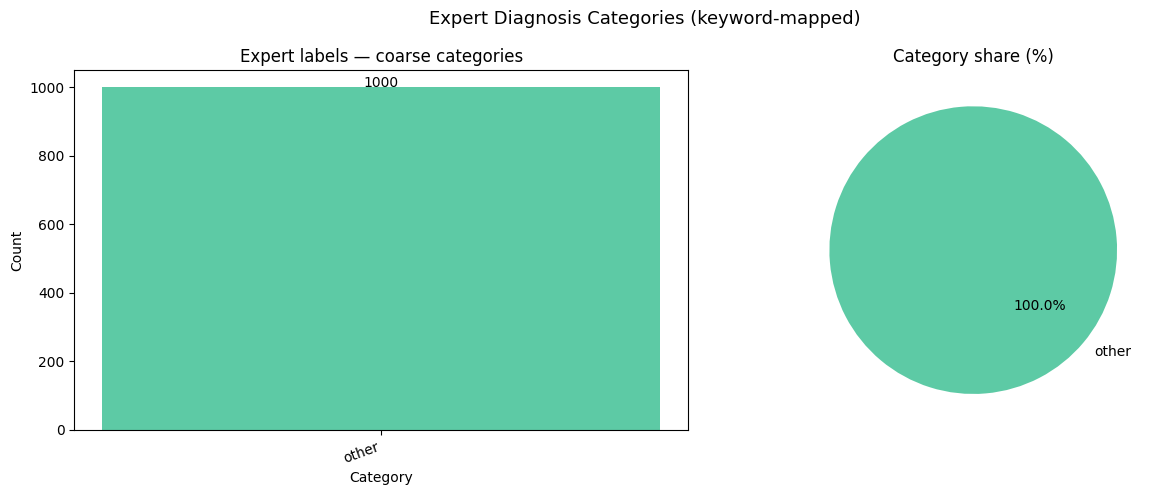

category
other    1000
Name: count, dtype: int64


In [ ]:
# ── CELL 10: Category distribution plot ──────────────────
cat_counts = df_expert['category'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = ['#5DCAA5','#EF9F27','#D85A30','#7F77DD','#378ADD','#888780']

axes[0].bar(cat_counts.index, cat_counts.values,
            color=colors[:len(cat_counts)])
axes[0].set_title("Expert labels — coarse categories", fontsize=12)
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Count")
for i, v in enumerate(cat_counts.values):
    axes[0].text(i, v + 2, str(v), ha='center', fontsize=10)
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=20, ha='right')

axes[1].pie(cat_counts.values,
            labels=cat_counts.index,
            autopct='%1.1f%%',
            colors=colors[:len(cat_counts)],
            startangle=140)
axes[1].set_title("Category share (%)", fontsize=12)

plt.suptitle("Expert Diagnosis Categories (keyword-mapped)", fontsize=13)
plt.tight_layout()
p = '/content/fig_categories.png'
plt.savefig(p, dpi=150, bbox_inches='tight')
figures['categories'] = p
plt.show()
print(cat_counts)

In [ ]:
# ── CELL 11: Bone-loss subset — keyword deep-dive ─────────
bone_df = df_expert[df_expert['category'] == 'bone_loss'].copy()
print(f"Bone loss records: {len(bone_df)}")
print(f"  = {len(bone_df)/len(df_expert)*100:.1f}% of expert annotations\n")

# Severity keywords within bone loss records
def severity_from_text(text):
    t = text.lower()
    if 'severe' in t:                          return 'severe'
    if 'moderate' in t:                        return 'moderate'
    if 'mild' in t or 'early' in t:           return 'mild'
    if 'generalized' in t:                     return 'generalized'
    return 'unspecified'

bone_df['severity'] = bone_df['raw_label'].apply(severity_from_text)
print("Bone loss severity breakdown:")
print(bone_df['severity'].value_counts())
report_data['bone_loss_count']    = len(bone_df)
report_data['bone_loss_severity'] = bone_df['severity'].value_counts().to_dict()

# Show 5 sample raw labels
print("\nSample bone loss labels:")
for _, row in bone_df.head(5).iterrows():
    print(f"  [{row['image_id']}] {row['raw_label'][:120]}")

Bone loss records: 0
  = 0.0% of expert annotations

Bone loss severity breakdown:
Series([], Name: count, dtype: int64)

Sample bone loss labels:


In [ ]:
# ── CELL 12: Bbox JSON analysis ───────────────────────────
# Build a DataFrame from teeth_bbox.json

bbox_records = []

if isinstance(bbox_raw, list):
    for item in bbox_raw:
        bbox_records.append(item)
elif isinstance(bbox_raw, dict):
    for img_id, val in bbox_raw.items():
        if isinstance(val, list):
            for tooth in val:
                tooth['image_id'] = img_id
                bbox_records.append(tooth)
        elif isinstance(val, dict):
            val['image_id'] = img_id
            bbox_records.append(val)

df_bbox = pd.DataFrame(bbox_records)
print(f"Bbox records: {len(df_bbox)}")
print(f"Columns     : {list(df_bbox.columns)}")
print(df_bbox.head(3).to_string())

report_data['bbox_records'] = len(df_bbox)

# How many unique images have bbox annotations?
id_col = next((c for c in ['image_id','img_id','filename','id']
               if c in df_bbox.columns), None)
if id_col:
    print(f"\nUnique images with bbox: {df_bbox[id_col].nunique()}")
    print(f"Avg teeth per image    : {len(df_bbox)/df_bbox[id_col].nunique():.1f}")
    report_data['bbox_unique_images']   = int(df_bbox[id_col].nunique())
    report_data['bbox_avg_per_image']   = round(
        len(df_bbox)/df_bbox[id_col].nunique(), 1)

Bbox records: 1000
Columns     : ['Label', 'External ID']
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

In [ ]:
# ── CELL 13: Bbox size distribution ──────────────────────
# Auto-detect bbox columns
bbox_col_candidates = {
    'x': ['x','x1','xmin','left'],
    'y': ['y','y1','ymin','top'],
    'w': ['w','width','bbox_w'],
    'h': ['h','height','bbox_h'],
}

def find_col(df, candidates):
    for c in candidates:
        if c in df.columns: return c
    return None

xc = find_col(df_bbox, bbox_col_candidates['x'])
yc = find_col(df_bbox, bbox_col_candidates['y'])
wc = find_col(df_bbox, bbox_col_candidates['w'])
hc = find_col(df_bbox, bbox_col_candidates['h'])

print(f"Bbox columns found → x:{xc}  y:{yc}  w:{wc}  h:{hc}")

if all([xc, yc, wc, hc]):
    widths  = pd.to_numeric(df_bbox[wc], errors='coerce').dropna()
    heights = pd.to_numeric(df_bbox[hc], errors='coerce').dropna()
    aspects = widths / (heights + 1e-6)

    report_data['bbox_w_mean'] = float(widths.mean())
    report_data['bbox_h_mean'] = float(heights.mean())
    report_data['bbox_w_range']= (float(widths.min()), float(widths.max()))
    report_data['bbox_h_range']= (float(heights.min()), float(heights.max()))

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].hist(widths,  bins=30, color='#7F77DD')
    axes[0].set_title("Bbox width (px)");  axes[0].set_xlabel("px")
    axes[1].hist(heights, bins=30, color='#7F77DD')
    axes[1].set_title("Bbox height (px)"); axes[1].set_xlabel("px")
    axes[2].hist(aspects, bins=30, color='#D85A30')
    axes[2].set_title("Aspect ratio w/h"); axes[2].set_xlabel("ratio")

    plt.suptitle("Tooth Bounding Box Statistics", fontsize=13)
    plt.tight_layout()
    p = '/content/fig_bbox.png'
    plt.savefig(p, dpi=150, bbox_inches='tight')
    figures['bbox'] = p
    plt.show()

    print(f"Width  : {widths.min():.0f}–{widths.max():.0f} px  "
          f"(mean {widths.mean():.0f})")
    print(f"Height : {heights.min():.0f}–{heights.max():.0f} px  "
          f"(mean {heights.mean():.0f})")
    print(f"Aspect : mean {aspects.mean():.2f}")
else:
    print("Could not auto-detect bbox columns.")
    print("Available:", list(df_bbox.columns))

Bbox columns found → x:None  y:None  w:None  h:None
Could not auto-detect bbox columns.
Available: ['Label', 'External ID']


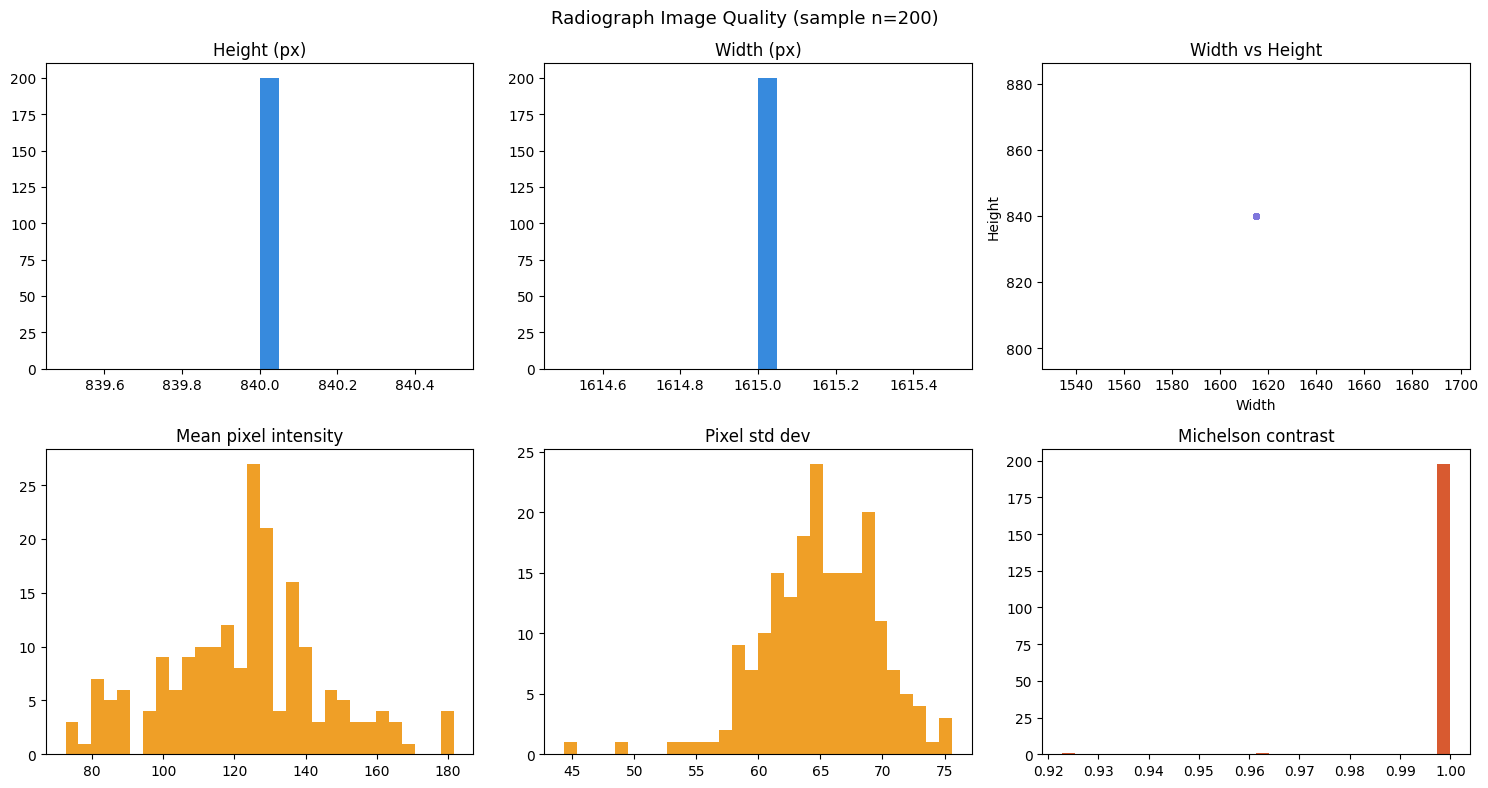

Height : 840–840 px  (mean 840)
Width  : 1615–1615 px  (mean 1615)
Contrast: 0.999 ± 0.006


In [ ]:
# ── CELL 14: Radiograph image quality audit ───────────────
sample_radio = random.sample(radio_files, min(200, len(radio_files)))

heights, widths, means, stds, contrasts = [], [], [], [], []

for p in sample_radio:
    try:
        img = np.array(PILImage.open(p).convert('L'))
        heights.append(img.shape[0])
        widths.append(img.shape[1])
        means.append(float(img.mean()))
        stds.append(float(img.std()))
        mn, mx = int(img.min()), int(img.max())
        contrasts.append((mx - mn) / (mx + mn + 1e-6))
    except Exception as e:
        print(f"  skip {p}: {e}")

report_data.update({
    'img_h_mean'  : np.mean(heights),
    'img_w_mean'  : np.mean(widths),
    'img_h_range' : (int(min(heights)), int(max(heights))),
    'img_w_range' : (int(min(widths)),  int(max(widths))),
    'mean_contrast': float(np.mean(contrasts)),
})

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes[0,0].hist(heights,   bins=20, color='#378ADD')
axes[0,0].set_title("Height (px)")
axes[0,1].hist(widths,    bins=20, color='#378ADD')
axes[0,1].set_title("Width (px)")
axes[0,2].scatter(widths, heights, alpha=0.4, s=15, color='#7F77DD')
axes[0,2].set_xlabel("Width"); axes[0,2].set_ylabel("Height")
axes[0,2].set_title("Width vs Height")
axes[1,0].hist(means,     bins=30, color='#EF9F27')
axes[1,0].set_title("Mean pixel intensity")
axes[1,1].hist(stds,      bins=30, color='#EF9F27')
axes[1,1].set_title("Pixel std dev")
axes[1,2].hist(contrasts, bins=30, color='#D85A30')
axes[1,2].set_title("Michelson contrast")

plt.suptitle("Radiograph Image Quality (sample n=200)", fontsize=13)
plt.tight_layout()
p = '/content/fig_quality.png'
plt.savefig(p, dpi=150, bbox_inches='tight')
figures['quality'] = p
plt.show()

print(f"Height : {min(heights)}–{max(heights)} px  (mean {np.mean(heights):.0f})")
print(f"Width  : {min(widths)}–{max(widths)} px  (mean {np.mean(widths):.0f})")
print(f"Contrast: {np.mean(contrasts):.3f} ± {np.std(contrasts):.3f}")

In [ ]:
# ── CELL 15: Mask pixel value audit ──────────────────────
# Maxillomandibular masks — what do pixel values encode?

maxillo_files = sorted([
    os.path.join(MAXILLO_DIR, f)
    for f in os.listdir(MAXILLO_DIR)
    if Path(f).suffix.lower() in {'.jpg','.jpeg','.png'}
])
teeth_mask_files = sorted([
    os.path.join(TEETH_DIR, f)
    for f in os.listdir(TEETH_DIR)
    if Path(f).suffix.lower() in {'.jpg','.jpeg','.png'}
])

print(f"Maxillomandibular masks : {len(maxillo_files)}")
print(f"Teeth masks             : {len(teeth_mask_files)}")

def audit_masks(files, label, n=30):
    all_unique = set()
    shapes     = []
    for p in random.sample(files, min(n, len(files))):
        m = np.array(PILImage.open(p).convert('L'))
        all_unique.update(np.unique(m).tolist())
        shapes.append(m.shape)
    print(f"\n{label}")
    print(f"  Unique pixel values (across {n} masks): "
          f"{sorted(all_unique)[:30]}")
    print(f"  Shape sample: {shapes[0]}")
    return sorted(all_unique)

maxillo_vals = audit_masks(maxillo_files, "Maxillomandibular masks")
teeth_vals   = audit_masks(teeth_mask_files, "Teeth masks")

report_data['maxillo_pixel_vals'] = maxillo_vals[:30]
report_data['teeth_pixel_vals']   = teeth_vals[:30]

Maxillomandibular masks : 1000
Teeth masks             : 308

Maxillomandibular masks
  Unique pixel values (across 30 masks): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
  Shape sample: (840, 1615)

Teeth masks
  Unique pixel values (across 30 masks): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
  Shape sample: (840, 1615)


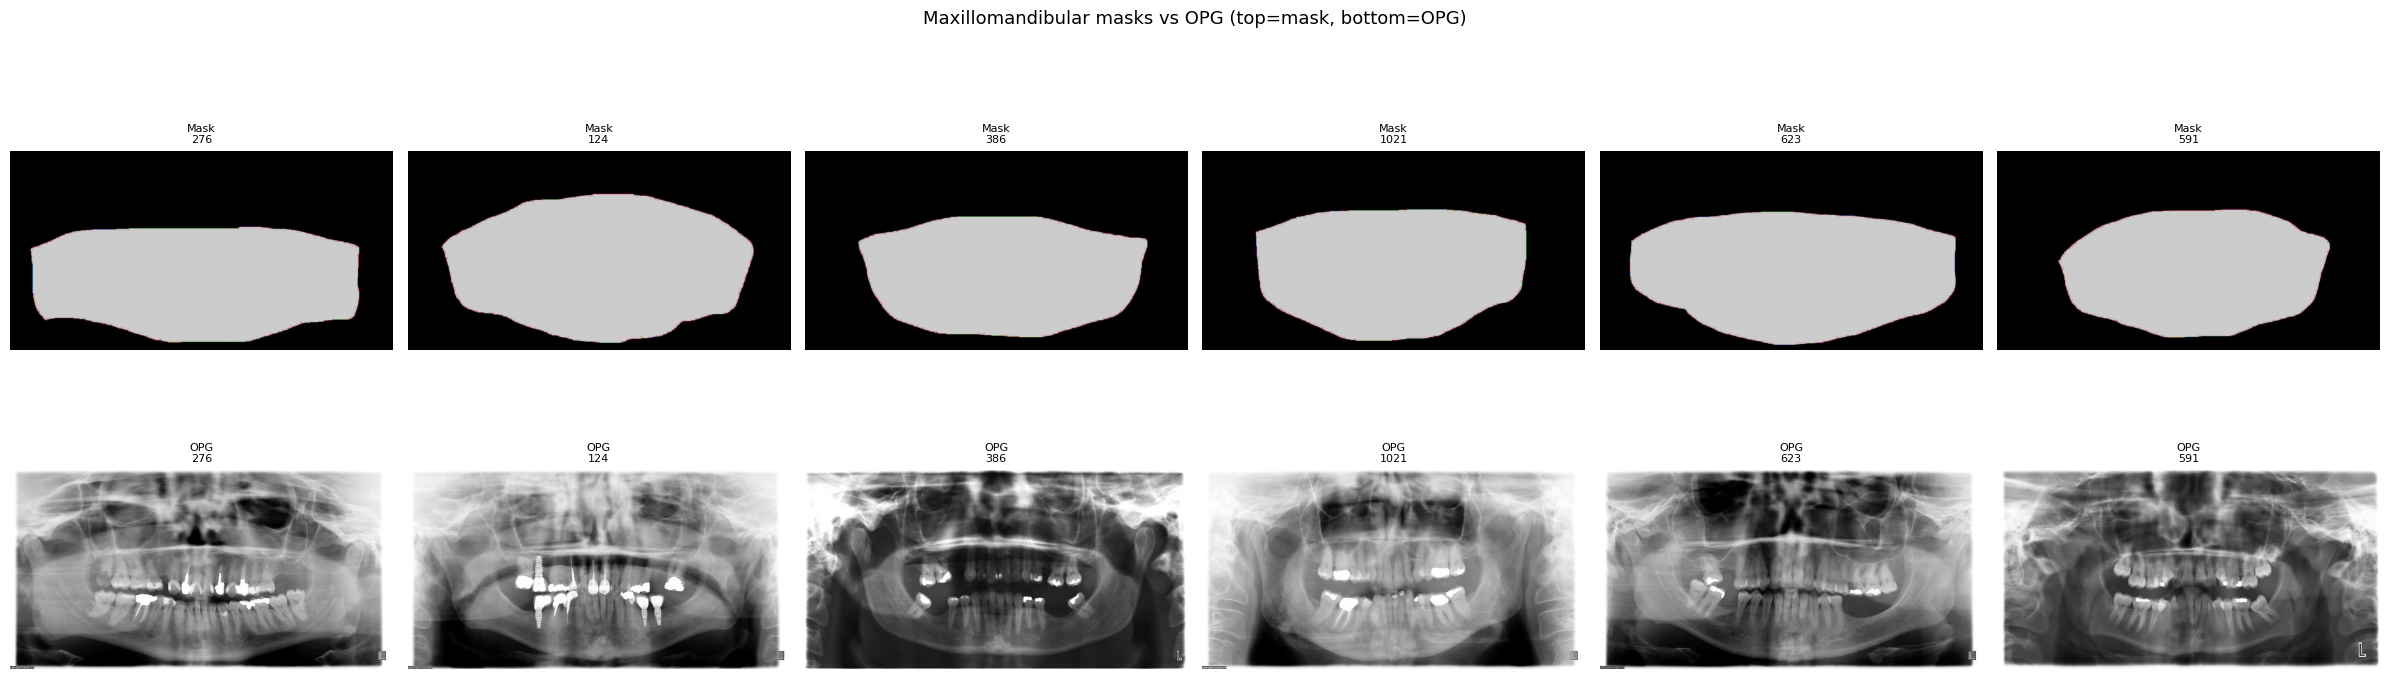

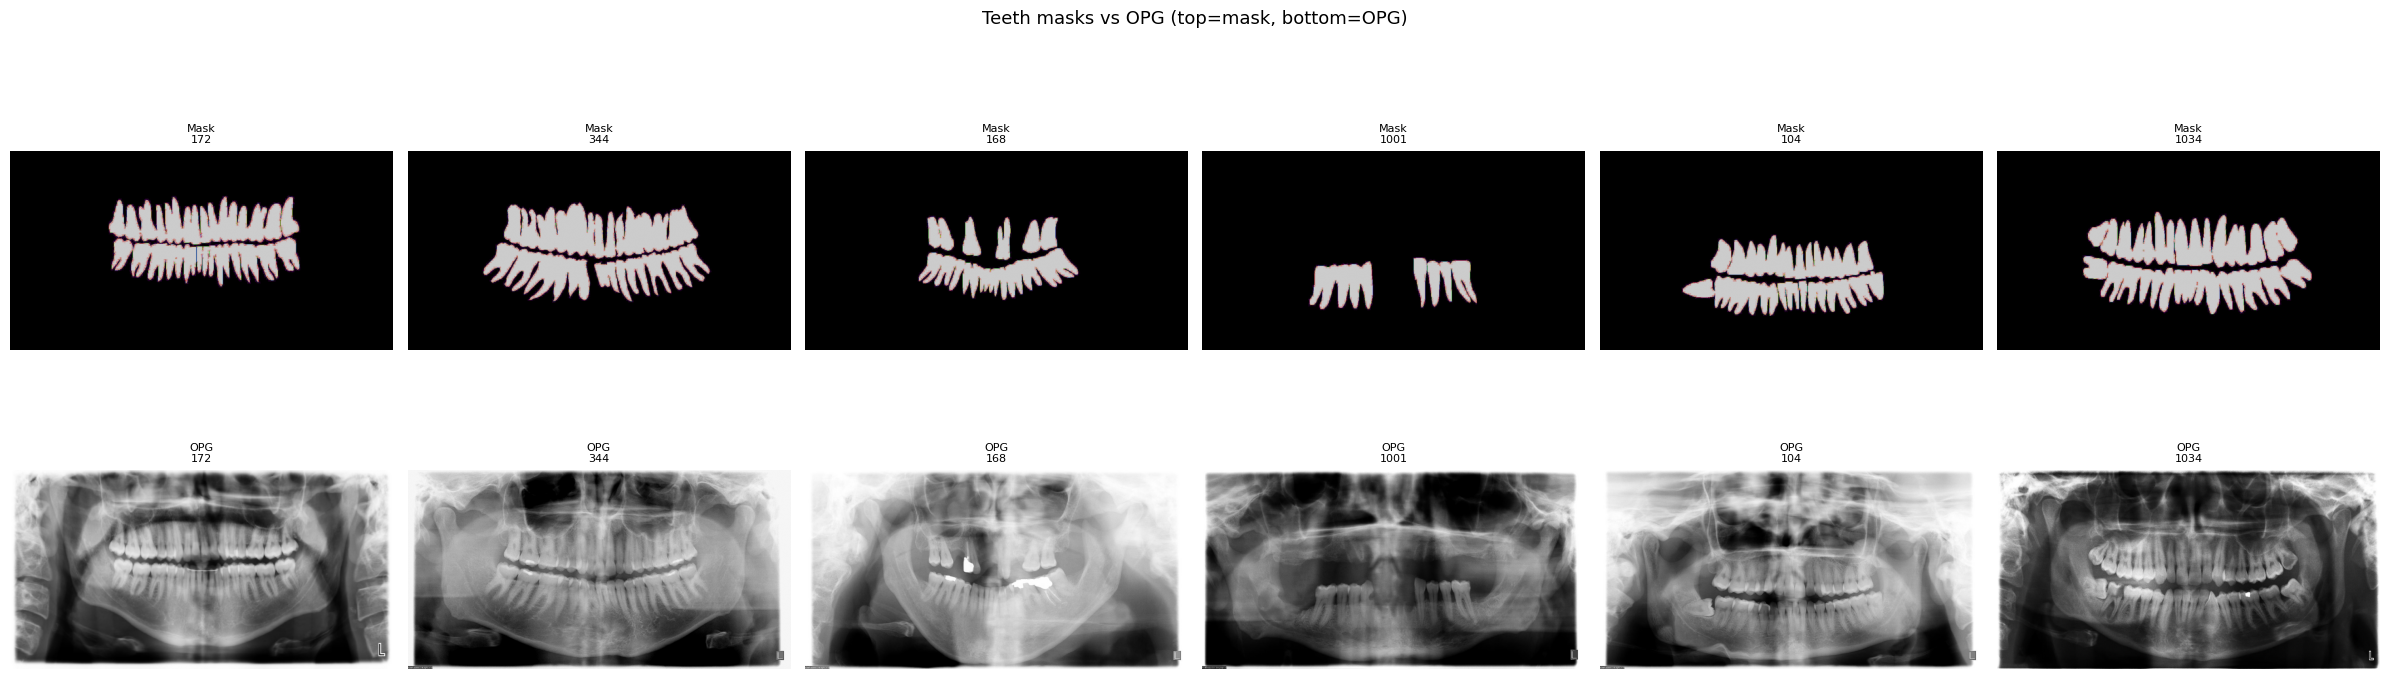

In [ ]:
# ── CELL 16: Mask visual inspection ──────────────────────
def show_mask_grid(mask_files, radio_dir, title, n=6):
    samples = random.sample(mask_files, min(n, len(mask_files)))
    fig, axes = plt.subplots(2, n, figsize=(4*n, 8))

    for col, mp in enumerate(samples):
        stem = Path(mp).stem
        # find matching radiograph
        rp = None
        for ext in ['.JPG','.jpg','.jpeg','.png']:
            cand = os.path.join(radio_dir, stem + ext)
            if os.path.exists(cand):
                rp = cand
                break

        mask = np.array(PILImage.open(mp).convert('L'))
        axes[0, col].imshow(mask, cmap='nipy_spectral',
                            vmin=0, vmax=max(1, mask.max()))
        axes[0, col].set_title(f"Mask\n{stem}", fontsize=8)
        axes[0, col].axis('off')

        if rp:
            radio = np.array(PILImage.open(rp).convert('L'))
            axes[1, col].imshow(radio, cmap='gray')
            axes[1, col].set_title(f"OPG\n{stem}", fontsize=8)
        else:
            axes[1, col].text(0.5, 0.5, 'OPG not found',
                              ha='center', va='center',
                              transform=axes[1, col].transAxes)
        axes[1, col].axis('off')

    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    return fig

fig_m = show_mask_grid(maxillo_files, RADIO_DIR,
                       "Maxillomandibular masks vs OPG (top=mask, bottom=OPG)")
p = '/content/fig_maxillo_masks.png'
fig_m.savefig(p, dpi=120, bbox_inches='tight')
figures['maxillo_masks'] = p
plt.show()

fig_t = show_mask_grid(teeth_mask_files, RADIO_DIR,
                       "Teeth masks vs OPG (top=mask, bottom=OPG)")
p = '/content/fig_teeth_masks.png'
fig_t.savefig(p, dpi=120, bbox_inches='tight')
figures['teeth_masks'] = p
plt.show()

In [ ]:
# ── CELL 17: Bbox overlay on OPG ─────────────────────────
# Visualise tooth bboxes drawn on actual radiographs

def overlay_bboxes(df_bbox, radio_dir, id_col, n=4):
    img_ids = df_bbox[id_col].dropna().unique()
    samples = random.sample(list(img_ids), min(n, len(img_ids)))

    fig, axes = plt.subplots(1, n, figsize=(5*n, 6))
    if n == 1: axes = [axes]

    for ax, img_id in zip(axes, samples):
        rp = None
        for ext in ['.JPG','.jpg','.jpeg','.png']:
            cand = os.path.join(radio_dir, str(img_id) + ext)
            if os.path.exists(cand):
                rp = cand; break

        if rp is None:
            ax.text(0.5, 0.5, f'No OPG\n{img_id}',
                    ha='center', va='center',
                    transform=ax.transAxes)
            ax.axis('off')
            continue

        radio = np.array(PILImage.open(rp).convert('RGB'))
        ax.imshow(radio, cmap='gray')

        teeth = df_bbox[df_bbox[id_col] == img_id]
        for _, row in teeth.iterrows():
            try:
                x = float(row[xc]); y = float(row[yc])
                w = float(row[wc]); h = float(row[hc])
                rect = mpatches.Rectangle(
                    (x, y), w, h,
                    linewidth=1.5, edgecolor='#EF9F27',
                    facecolor='none')
                ax.add_patch(rect)
                # tooth label if available
                lbl_col = next((c for c in ['label','tooth_id','fdi','class']
                                if c in row.index), None)
                if lbl_col:
                    ax.text(x, y - 4, str(row[lbl_col]),
                            color='#EF9F27', fontsize=6)
            except:
                pass
        ax.set_title(f"ID: {img_id}  ({len(teeth)} teeth)", fontsize=9)
        ax.axis('off')

    plt.suptitle("Tooth bounding boxes overlaid on OPG", fontsize=12)
    plt.tight_layout()
    return fig

if id_col and all([xc, yc, wc, hc]):
    fig_ov = overlay_bboxes(df_bbox, RADIO_DIR, id_col)
    p = '/content/fig_bbox_overlay.png'
    fig_ov.savefig(p, dpi=130, bbox_inches='tight')
    figures['bbox_overlay'] = p
    plt.show()
else:
    print("Skipping overlay — bbox columns not confirmed yet")

Skipping overlay — bbox columns not confirmed yet


  COVERAGE MATRIX
  OPG only                             1000  ██████████████████████████████
  OPG + maxillo mask                   1000  ██████████████████████████████
  OPG + teeth mask                      308  █████████
  OPG + expert label                      0  
  OPG + bbox                              0  
  OPG + teeth mask + expert               0  
  OPG + bbox + expert                     0  
  FULL (OPG+teeth+bbox+expert)            0  


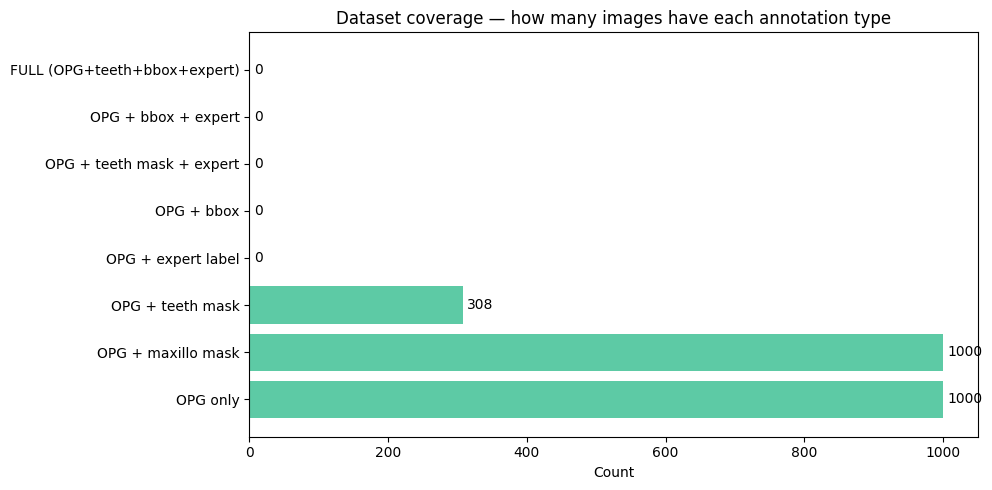

In [ ]:
# ── CELL 18: Coverage matrix ──────────────────────────────
# Which IDs have: OPG / maxillo mask / teeth mask /
#                expert annotation / bbox annotation

radio_set  = set(Path(f).stem for f in radio_files)

maxillo_set = set(Path(f).stem
    for f in os.listdir(MAXILLO_DIR)
    if Path(f).suffix.lower() in {'.jpg','.jpeg','.png'})

teeth_set = set(Path(f).stem
    for f in os.listdir(TEETH_DIR)
    if Path(f).suffix.lower() in {'.jpg','.jpeg','.png'})

expert_set = set(df_expert['image_id'].astype(str).str.strip())

bbox_set = (set(df_bbox[id_col].astype(str).str.strip())
            if id_col else set())

all_ids = radio_set

coverage = {
    'OPG only'                    : len(radio_set),
    'OPG + maxillo mask'          : len(radio_set & maxillo_set),
    'OPG + teeth mask'            : len(radio_set & teeth_set),
    'OPG + expert label'          : len(radio_set & expert_set),
    'OPG + bbox'                  : len(radio_set & bbox_set),
    'OPG + teeth mask + expert'   : len(radio_set & teeth_set & expert_set),
    'OPG + bbox + expert'         : len(radio_set & bbox_set & expert_set),
    'FULL (OPG+teeth+bbox+expert)': len(radio_set & teeth_set
                                        & bbox_set & expert_set),
}

print("=" * 55)
print("  COVERAGE MATRIX")
print("=" * 55)
for k, v in coverage.items():
    bar = '█' * int(v / len(radio_set) * 30)
    print(f"  {k:36s} {v:4d}  {bar}")

report_data['coverage'] = coverage

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(list(coverage.keys()), list(coverage.values()),
               color='#5DCAA5')
ax.set_xlabel("Count")
ax.set_title("Dataset coverage — how many images have each annotation type")
ax.bar_label(bars, padding=3)
plt.tight_layout()
p = '/content/fig_coverage.png'
plt.savefig(p, dpi=150, bbox_inches='tight')
figures['coverage'] = p
plt.show()

In [ ]:
# ── CELL 19: FDI / tooth label check in bbox JSON ─────────
# Check whether bbox records have FDI numbers

fdi_candidates = ['fdi','tooth_id','label','class','tooth','num',
                  'tooth_num','FDI','category']
fdi_col = next((c for c in fdi_candidates if c in df_bbox.columns), None)

if fdi_col:
    fdi_vals = df_bbox[fdi_col].dropna()
    print(f"FDI/tooth column found: '{fdi_col}'")
    print(f"Unique values ({len(fdi_vals.unique())}): "
          f"{sorted(fdi_vals.unique())[:40]}")

    # Coverage per tooth position
    counts = fdi_vals.value_counts().sort_index()

    fig, ax = plt.subplots(figsize=(14, 4))
    ax.bar(counts.index.astype(str), counts.values, color='#5DCAA5')
    ax.set_title("Sample count per tooth label / FDI position")
    ax.set_xlabel("Tooth label"); ax.set_ylabel("Count")
    plt.xticks(rotation=45, fontsize=7)
    plt.tight_layout()
    p = '/content/fig_fdi.png'
    plt.savefig(p, dpi=150, bbox_inches='tight')
    figures['fdi'] = p
    plt.show()
    report_data['fdi_col']    = fdi_col
    report_data['fdi_unique'] = len(fdi_vals.unique())
else:
    print("No FDI column found in bbox JSON.")
    print("Available columns:", list(df_bbox.columns))
    report_data['fdi_col'] = 'NOT FOUND'

No FDI column found in bbox JSON.
Available columns: ['Label', 'External ID']


In [ ]:
# ── CELL 20: Expanded crop simulation ─────────────────────
# Simulate what YOLO will feed to the bone loss model.
# Use GT bboxes as proxy. Show tight vs expanded side by side.

def expanded_crop(img_arr, x, y, w, h, factor):
    H, W = img_arr.shape[:2]
    cx, cy = x + w/2, y + h/2
    nw, nh = w * factor, h * factor
    x1 = max(0, int(cx - nw/2))
    y1 = max(0, int(cy - nh/2))
    x2 = min(W,  int(cx + nw/2))
    y2 = min(H,  int(cy + nh/2))
    return img_arr[y1:y2, x1:x2]

if id_col and all([xc, yc, wc, hc]):
    img_ids = df_bbox[id_col].dropna().unique()
    samples = random.sample(list(img_ids), min(5, len(img_ids)))

    fig, axes = plt.subplots(len(samples), 3,
                             figsize=(10, 3.5*len(samples)))
    if len(samples) == 1: axes = [axes]

    for row_i, img_id in enumerate(samples):
        rp = None
        for ext in ['.JPG','.jpg','.jpeg','.png']:
            cand = os.path.join(RADIO_DIR, str(img_id) + ext)
            if os.path.exists(cand): rp = cand; break

        if rp is None:
            for ax in axes[row_i]: ax.axis('off')
            continue

        radio = np.array(PILImage.open(rp).convert('L'))
        teeth = df_bbox[df_bbox[id_col] == img_id]
        row_b = teeth.iloc[len(teeth)//2]  # pick middle tooth

        try:
            x,y,w,h = (float(row_b[xc]), float(row_b[yc]),
                       float(row_b[wc]), float(row_b[hc]))

            tight    = cv2.resize(
                expanded_crop(radio,x,y,w,h,1.0),(224,224))
            expanded = cv2.resize(
                expanded_crop(radio,x,y,w,h,1.8),(224,224))
            jittered = cv2.resize(
                expanded_crop(radio,
                    x*(1+random.uniform(-0.15,0.15)),
                    y*(1+random.uniform(-0.15,0.15)),
                    w, h, 1.8),(224,224))

            axes[row_i][0].imshow(tight,    cmap='gray')
            axes[row_i][0].set_title(f"Tight crop\n(caries model input)", fontsize=8)
            axes[row_i][1].imshow(expanded, cmap='gray')
            axes[row_i][1].set_title(f"Expanded 1.8x\n(bone loss input)",  fontsize=8)
            axes[row_i][2].imshow(jittered, cmap='gray')
            axes[row_i][2].set_title(f"Expanded + 15% jitter\n(YOLO simulation)", fontsize=8)
        except Exception as e:
            print(f"  crop error {img_id}: {e}")
            for ax in axes[row_i]: ax.axis('off')

        for ax in axes[row_i]: ax.axis('off')

    plt.suptitle("Crop simulation: tight vs expanded vs YOLO-jittered",
                 fontsize=12)
    plt.tight_layout()
    p = '/content/fig_crops.png'
    plt.savefig(p, dpi=130, bbox_inches='tight')
    figures['crops'] = p
    plt.show()
else:
    print("Skipping crop simulation — bbox not parsed")

Skipping crop simulation — bbox not parsed


In [ ]:
# ── CELL 21: Summary printout ─────────────────────────────
print("\n" + "=" * 65)
print("  TUFTS DATASET — FINAL EXPLORATION SUMMARY")
print("=" * 65)

print(f"\n  INVENTORY")
for k, v in report_data.get('inventory', {}).items():
    print(f"    {k:26s}: {v}")

print(f"\n  ANNOTATIONS")
print(f"    Expert records parsed     : {report_data.get('expert_records','?')}")
print(f"    Bbox records              : {report_data.get('bbox_records','?')}")
print(f"    Avg teeth per image       : {report_data.get('bbox_avg_per_image','?')}")
print(f"    FDI column                : {report_data.get('fdi_col','?')}")

print(f"\n  DIAGNOSIS CATEGORIES")
for k, v in report_data.get('category_counts',{}).items():
    print(f"    {k:26s}: {v}")

print(f"\n  BONE LOSS")
print(f"    Total bone loss records   : {report_data.get('bone_loss_count','?')}")
for k, v in report_data.get('bone_loss_severity',{}).items():
    print(f"    Severity — {k:15s}: {v}")

print(f"\n  IMAGE QUALITY")
print(f"    Avg size (H x W)          : "
      f"{report_data.get('img_h_mean',0):.0f} x "
      f"{report_data.get('img_w_mean',0):.0f} px")
print(f"    Mean contrast             : {report_data.get('mean_contrast',0):.3f}")

print(f"\n  COVERAGE MATRIX")
for k, v in report_data.get('coverage',{}).items():
    print(f"    {k:36s}: {v}")

print("\n" + "=" * 65)


  TUFTS DATASET — FINAL EXPLORATION SUMMARY

  INVENTORY
    Radiographs               : 1000
    Maxillomandibular         : 1000
    Teeth masks               : 308
    Expert masks              : 439
    Expert gaze               : 1000
    Student gaze              : 941

  ANNOTATIONS
    Expert records parsed     : 1000
    Bbox records              : 1000
    Avg teeth per image       : ?
    FDI column                : NOT FOUND

  DIAGNOSIS CATEGORIES
    other                     : 1000

  BONE LOSS
    Total bone loss records   : 0

  IMAGE QUALITY
    Avg size (H x W)          : 840 x 1615 px
    Mean contrast             : 0.999

  COVERAGE MATRIX
    OPG only                            : 1000
    OPG + maxillo mask                  : 1000
    OPG + teeth mask                    : 308
    OPG + expert label                  : 0
    OPG + bbox                          : 0
    OPG + teeth mask + expert           : 0
    OPG + bbox + expert                 : 0
    FULL (OPG+

In [ ]:
# ── CELL 22: PDF report ───────────────────────────────────
from fpdf import FPDF

def safe_img_path(path, max_w=1800):
    safe = path.replace('.png','_rs.png')
    img  = PILImage.open(path)
    if img.width > max_w:
        r   = max_w / img.width
        img = img.resize((max_w, int(img.height*r)), PILImage.LANCZOS)
    img.save(safe, dpi=(150,150))
    return safe

class PDF(FPDF):
    def header(self):
        self.set_font('DV','B',13)
        self.cell(0,10,'Tufts Dental Dataset - Exploration Report',
                  ln=True, align='C')
        self.set_font('DV','',9)
        self.cell(0,6,
            f"Generated: {datetime.datetime.now().strftime('%Y-%m-%d %H:%M')}",
            ln=True, align='C')
        self.line(10, self.get_y(), 200, self.get_y())
        self.ln(3)

    def footer(self):
        self.set_y(-12)
        self.set_font('DV','',8)
        self.cell(0,8,f'Page {self.page_no()}',align='C')

    def sec(self, t):
        self.set_font('DV','B',11)
        self.set_fill_color(220,220,240)
        self.cell(0,8,t,ln=True,fill=True)
        self.ln(1)

    def kv(self, label, val, hi=False):
        if hi: self.set_fill_color(255,243,205)
        self.set_font('DV','B',10)
        self.cell(90,6,label+':',fill=hi)
        self.set_font('DV','',10)
        self.cell(0,6,str(val),ln=True,fill=hi)

    def fig(self, path, title, w=185):
        self.add_page()
        self.sec(title)
        if path and os.path.exists(path):
            self.image(safe_img_path(path), x=10, w=w)
        else:
            self.set_font('DV','',10)
            self.set_text_color(180,0,0)
            self.cell(0,8,f'[Not generated]',ln=True)
            self.set_text_color(0,0,0)

pdf = PDF()
pdf.add_font('DV','',  '/content/DejaVuSans.ttf',      uni=True)
pdf.add_font('DV','B', '/content/DejaVuSans-Bold.ttf', uni=True)
pdf.set_auto_page_break(auto=True, margin=14)
pdf.add_page()

# ── S1: Inventory ─────────────────────────────────────────
pdf.sec('1. File Inventory')
for k,v in report_data.get('inventory',{}).items():
    pdf.kv(k, v)
pdf.kv('Total radiographs', report_data.get('total_radiographs','?'))
pdf.ln(3)

# ── S2: Image quality ─────────────────────────────────────
pdf.sec('2. Radiograph Image Quality')
pdf.kv('Avg height', f"{report_data.get('img_h_mean',0):.0f} px  "
       f"{report_data.get('img_h_range','')}")
pdf.kv('Avg width',  f"{report_data.get('img_w_mean',0):.0f} px  "
       f"{report_data.get('img_w_range','')}")
pdf.kv('Mean Michelson contrast', f"{report_data.get('mean_contrast',0):.3f}")
pdf.ln(3)

# ── S3: Annotation summary ────────────────────────────────
pdf.sec('3. Annotation Summary')
pdf.kv('Expert records',      report_data.get('expert_records','?'))
pdf.kv('Bbox records',        report_data.get('bbox_records','?'))
pdf.kv('Avg teeth per image', report_data.get('bbox_avg_per_image','?'))
pdf.kv('FDI column found',    report_data.get('fdi_col','?'), hi=True)
pdf.ln(3)

# ── S4: Diagnosis categories ──────────────────────────────
pdf.sec('4. Expert Diagnosis Categories')
pdf.set_font('DV','B',10)
pdf.set_fill_color(200,200,220)
pdf.cell(80,7,'Category',border=1,fill=True)
pdf.cell(25,7,'Count',   border=1,fill=True)
pdf.cell(0, 7,'%',       border=1,fill=True,ln=True)
total_exp = report_data.get('expert_records',1)
for cat,cnt in report_data.get('category_counts',{}).items():
    pdf.set_font('DV','',10)
    pdf.cell(80,6,str(cat),  border=1)
    pdf.cell(25,6,str(cnt),  border=1)
    pdf.cell(0, 6,f"{cnt/total_exp*100:.1f}%",border=1,ln=True)
pdf.ln(3)

# ── S5: Bone loss deep-dive ───────────────────────────────
pdf.sec('5. Bone Loss — Subset Analysis')
pdf.kv('Total bone loss records',
       f"{report_data.get('bone_loss_count','?')}  "
       f"({report_data.get('bone_loss_count',0)/total_exp*100:.1f}%)", hi=True)
pdf.ln(2)
pdf.set_font('DV','B',10)
pdf.cell(60,7,'Severity',border=1,fill=False)
pdf.cell(25,7,'Count',   border=1,fill=False,ln=True)
for sev,cnt in report_data.get('bone_loss_severity',{}).items():
    pdf.set_font('DV','',10)
    pdf.cell(60,6,str(sev),border=1)
    pdf.cell(25,6,str(cnt),border=1,ln=True)
pdf.ln(3)

# ── S6: Mask analysis ─────────────────────────────────────
pdf.sec('6. Mask Analysis')
pdf.kv('Maxillomandibular pixel values',
       str(report_data.get('maxillo_pixel_vals','?'))[:80])
pdf.kv('Teeth mask pixel values',
       str(report_data.get('teeth_pixel_vals','?'))[:80])
pdf.ln(2)
pdf.set_font('DV','',10)
pdf.multi_cell(0,6,
    'Maxillomandibular masks cover full jaw — useful for jaw segmentation. '
    'Teeth masks are the direct input for the bone loss model (only 300 images). '
    'Pixel values must be verified: if values = tooth IDs (1-32), masks are '
    'instance segmentation. If values = class IDs, masks are semantic.')
pdf.ln(3)

# ── S7: Coverage matrix ───────────────────────────────────
pdf.sec('7. Dataset Coverage Matrix')
for k,v in report_data.get('coverage',{}).items():
    hi = 'FULL' in k
    pdf.kv(k, v, hi=hi)
pdf.ln(3)

# ── S8: Pipeline decision ─────────────────────────────────
pdf.sec('8. Pipeline Decision')
cov = report_data.get('coverage',{})
full = cov.get('FULL (OPG+teeth+bbox+expert)', 0)
pdf.set_font('DV','B',11)
if full > 50:
    pdf.set_text_color(0,120,0)
    pdf.multi_cell(0,8,
        f'DECISION: Proceed with U-Net on {full} fully-annotated samples.')
else:
    pdf.set_text_color(160,90,0)
    pdf.multi_cell(0,8,
        f'DECISION: Only {full} fully-annotated samples. '
        f'Consider classification-only approach or data augmentation.')
pdf.set_text_color(0,0,0)
pdf.ln(2)
pdf.set_font('DV','',10)
next_steps = [
    '1. Confirm pixel value encoding in teeth_mask (tooth ID vs class ID).',
    '2. Map expert free-text labels to per-tooth severity using bbox image_id.',
    '3. Use bbox JSON to generate expanded crops (1.8x) for bone loss model.',
    '4. Add +/-15% bbox jitter during training to simulate YOLO noise.',
    '5. Stratified train/val split on the 300 teeth-mask images.',
    '6. Set per-class weights: w_i = total / (n_classes x count_i).',
    '7. Evaluation target: per-class F1 >= 0.70 for all severity levels.',
]
for s in next_steps:
    pdf.multi_cell(0,6,s)
    pdf.ln(1)

# ── Figures ───────────────────────────────────────────────
fig_pages = [
    (figures.get('categories'),    '9.1  Expert Diagnosis Categories'),
    (figures.get('quality'),       '9.2  Radiograph Image Quality'),
    (figures.get('bbox'),          '9.3  Tooth Bounding Box Statistics'),
    (figures.get('bbox_overlay'),  '9.4  Bbox Overlaid on OPG'),
    (figures.get('coverage'),      '9.5  Dataset Coverage Matrix'),
    (figures.get('maxillo_masks'), '9.6  Maxillomandibular Masks vs OPG'),
    (figures.get('teeth_masks'),   '9.7  Teeth Masks vs OPG'),
    (figures.get('crops'),         '9.8  Crop Simulation'),
    (figures.get('fdi'),           '9.9  Tooth Label / FDI Coverage'),
]
for path, title in fig_pages:
    pdf.fig(path, title)

# ── Save ──────────────────────────────────────────────────
out = '/content/tufts_exploration_v2.pdf'
pdf.output(out)
print(f'✅ Report saved: {out}  '
      f'({os.path.getsize(out)/1024:.0f} KB)')

from google.colab import files
files.download(out)

/tmp/ipykernel_5028/1616635139.py:55: DeprecationWarning: "uni" parameter is deprecated since v2.5.1 and will be removed in a future release
  pdf.add_font('DV','',  '/content/DejaVuSans.ttf',      uni=True)
/tmp/ipykernel_5028/1616635139.py:56: DeprecationWarning: "uni" parameter is deprecated since v2.5.1 and will be removed in a future release
  pdf.add_font('DV','B', '/content/DejaVuSans-Bold.ttf', uni=True)
/tmp/ipykernel_5028/1616635139.py:16: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=True use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  self.cell(0,10,'Tufts Dental Dataset - Exploration Report',
/tmp/ipykernel_5028/1616635139.py:19: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=True use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  self.cell(0,6,
/tmp/ipykernel_5028/1616635139.py:33: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=True use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  self.cel

✅ Report saved: /content/tufts_exploration_v2.pdf  (984 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

JSON type: list
List length: 1000
First item: {
  "Label": {
    "objects": [
      {
        "title": "None",
        "value": "none",
        "classifications": "none",
        "polygons": "none"
      }
    ],
    "classifications": []
  },
  "Description": "Within normal limits",
  "External ID": "53.JPG"
}

Sample radiograph stems: ['1', '100', '1000', '1001', '1002', '1004', '1007', '1008', '1009', '101']

Expert mask files   : 439
Sample filenames    : ['1.JPG', '100.JPG', '1000.JPG', '1001.JPG', '1002.JPG', '1004.JPG', '1007.JPG', '1008.JPG']
Unique pixel values (50 samples): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 42, 213, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255]


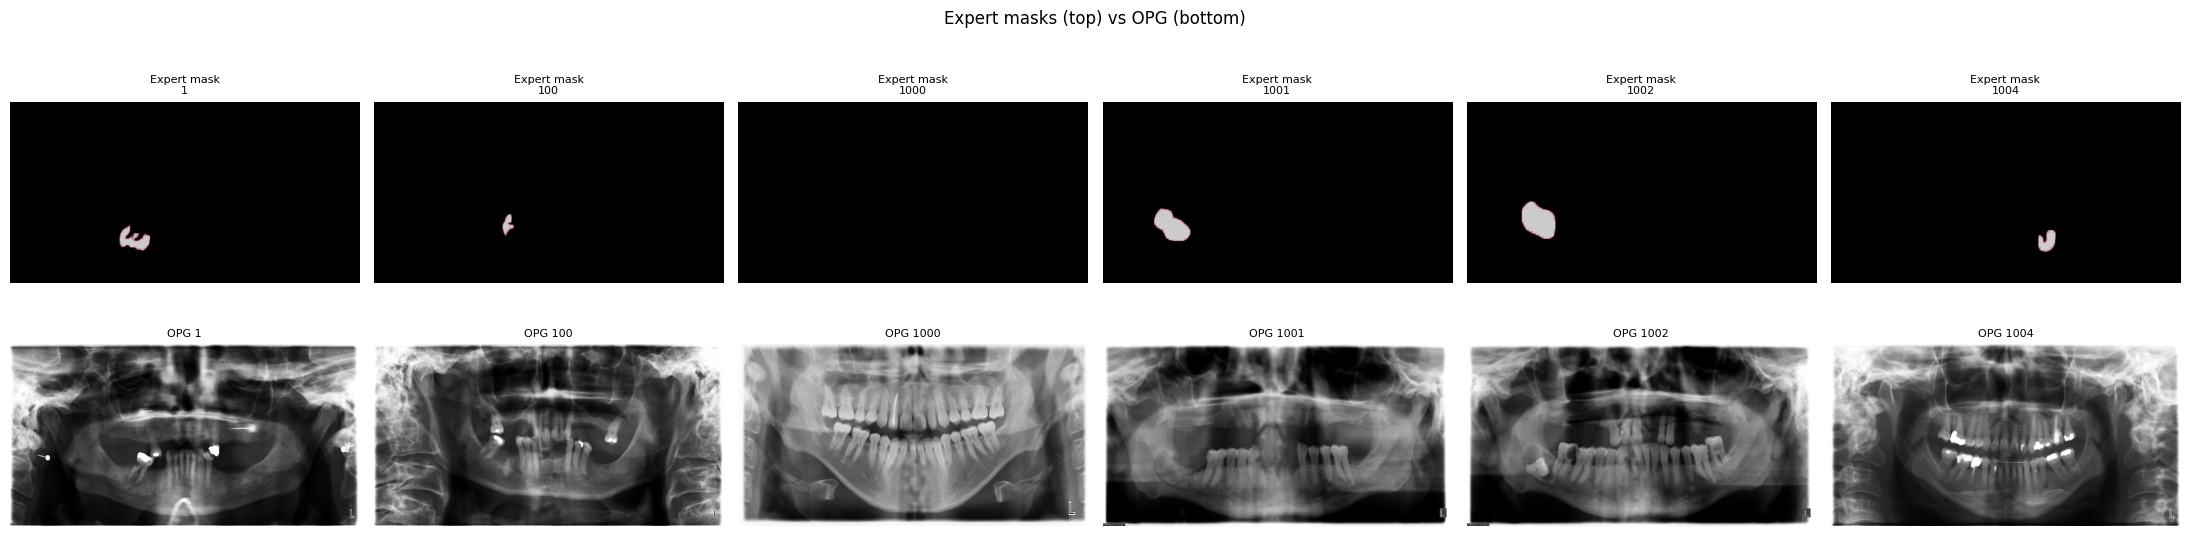


Bbox JSON type: list
List length: 1000
First item: {
  "Label": {
    "objects": [
      {
        "title": "1",
        "bounding box": [
          314,
          476,
          376,
          533
        ]
      },
      {
        "title": "2",
        "bounding box": [
          368,
          484,
          480,
          554
        ]
      },
      {
        "title": "3",
        "bounding box": [
          365,
          541,
          505,
          605
        ]
      },
      {
        "title": "4",
        "bounding box": [
          371,
          641,
          372,
          642
        ]
      },
      {
        "title": "5",
        "bounding box": [
          366,
          649,
          515,
          700
        ]
      },
      {
        "title": "6",
        "bounding box": [
          339,
          695,
          508,
          738
        ]
      },
      {
        "title": "7",
        "bounding box": [
          376,
          735,
          521,
          7

In [ ]:
# ── CRITICAL: Fix ID mismatch + inspect expert masks ──────

import json, os, numpy as np
from pathlib import Path
from PIL import Image as PILImage
import matplotlib.pyplot as plt

# ── 1. Show actual JSON keys vs actual filenames ───────────
with open(EXPERT_JSON) as f:
    expert_raw = json.load(f)

print("JSON type:", type(expert_raw).__name__)

if isinstance(expert_raw, dict):
    sample_keys = list(expert_raw.keys())[:10]
    print("Sample JSON keys    :", sample_keys)
    print("First record value  :")
    first_val = expert_raw[sample_keys[0]]
    print(json.dumps(first_val, indent=2)
          if isinstance(first_val, dict)
          else str(first_val)[:500])

elif isinstance(expert_raw, list):
    print("List length:", len(expert_raw))
    print("First item:", json.dumps(expert_raw[0], indent=2))

# Actual radiograph stems
radio_stems = set(Path(f).stem for f in os.listdir(RADIO_DIR))
print("\nSample radiograph stems:", sorted(list(radio_stems))[:10])

# ── 2. Expert mask folder — full audit ────────────────────
expert_mask_files = sorted([
    os.path.join(EXPERT_MASK, f)
    for f in os.listdir(EXPERT_MASK)
    if Path(f).suffix.lower() in {'.jpg','.jpeg','.png'}
])

print(f"\nExpert mask files   : {len(expert_mask_files)}")
print("Sample filenames    :", [Path(f).name for f in expert_mask_files[:8]])

# Pixel value audit on expert masks
all_vals = set()
for p in expert_mask_files[:50]:
    m = np.array(PILImage.open(p).convert('L'))
    all_vals.update(np.unique(m).tolist())
print(f"Unique pixel values (50 samples): {sorted(all_vals)}")

# ── 3. Visualize 6 expert masks vs OPG ────────────────────
fig, axes = plt.subplots(2, 6, figsize=(22, 6))
samples = expert_mask_files[:6]

for col, mp in enumerate(samples):
    stem = Path(mp).stem
    mask = np.array(PILImage.open(mp).convert('L'))

    axes[0, col].imshow(mask, cmap='nipy_spectral',
                        vmin=0, vmax=max(1, mask.max()))
    axes[0, col].set_title(f"Expert mask\n{stem}", fontsize=8)
    axes[0, col].axis('off')

    rp = None
    for ext in ['.JPG', '.jpg', '.jpeg', '.png']:
        cand = os.path.join(RADIO_DIR, stem + ext)
        if os.path.exists(cand): rp = cand; break

    if rp:
        radio = np.array(PILImage.open(rp).convert('L'))
        axes[1, col].imshow(radio, cmap='gray')
    else:
        axes[1, col].text(0.5, 0.5, 'No OPG match',
                          ha='center', transform=axes[1,col].transAxes)
    axes[1, col].set_title(f"OPG {stem}", fontsize=8)
    axes[1, col].axis('off')

plt.suptitle("Expert masks (top) vs OPG (bottom)", fontsize=12)
plt.tight_layout()
plt.savefig('/content/expert_mask_inspect.png', dpi=130, bbox_inches='tight')
plt.show()

# ── 4. Bbox JSON key inspection ───────────────────────────
with open(BBOX_JSON) as f:
    bbox_raw = json.load(f)

print("\nBbox JSON type:", type(bbox_raw).__name__)
if isinstance(bbox_raw, dict):
    bbox_keys = list(bbox_raw.keys())[:10]
    print("Sample bbox keys:", bbox_keys)
    print("First bbox record:")
    print(json.dumps(bbox_raw[bbox_keys[0]], indent=2)
          if isinstance(bbox_raw[bbox_keys[0]], dict)
          else str(bbox_raw[bbox_keys[0]])[:500])
elif isinstance(bbox_raw, list):
    print("List length:", len(bbox_raw))
    print("First item:", json.dumps(bbox_raw[0], indent=2))

Expert records parsed: 1000
Has finding          : 340
Normal (no finding)  : 660

Sample records:
  stem   ext_id           description  has_finding  n_objects
0   53   53.JPG  Within normal limits        False          1
1  823  823.JPG  Within normal limits        False          1
2   85   85.JPG  Within normal limits        False          1
3  855  855.JPG  Within normal limits        False          1
4  117  117.JPG  Within normal limits        False          1

Bbox records parsed: 26005
Unique images      : 968
Avg teeth / image  : 26.9
Tooth IDs present  : ['1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '3', '30', '31', '32', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T']
  stem tooth_id    x    y   w    h   x1   y1   x2   y2
0  797        1  476  314  57   62  476  314  533  376
1  797        2  484  368  70  112 

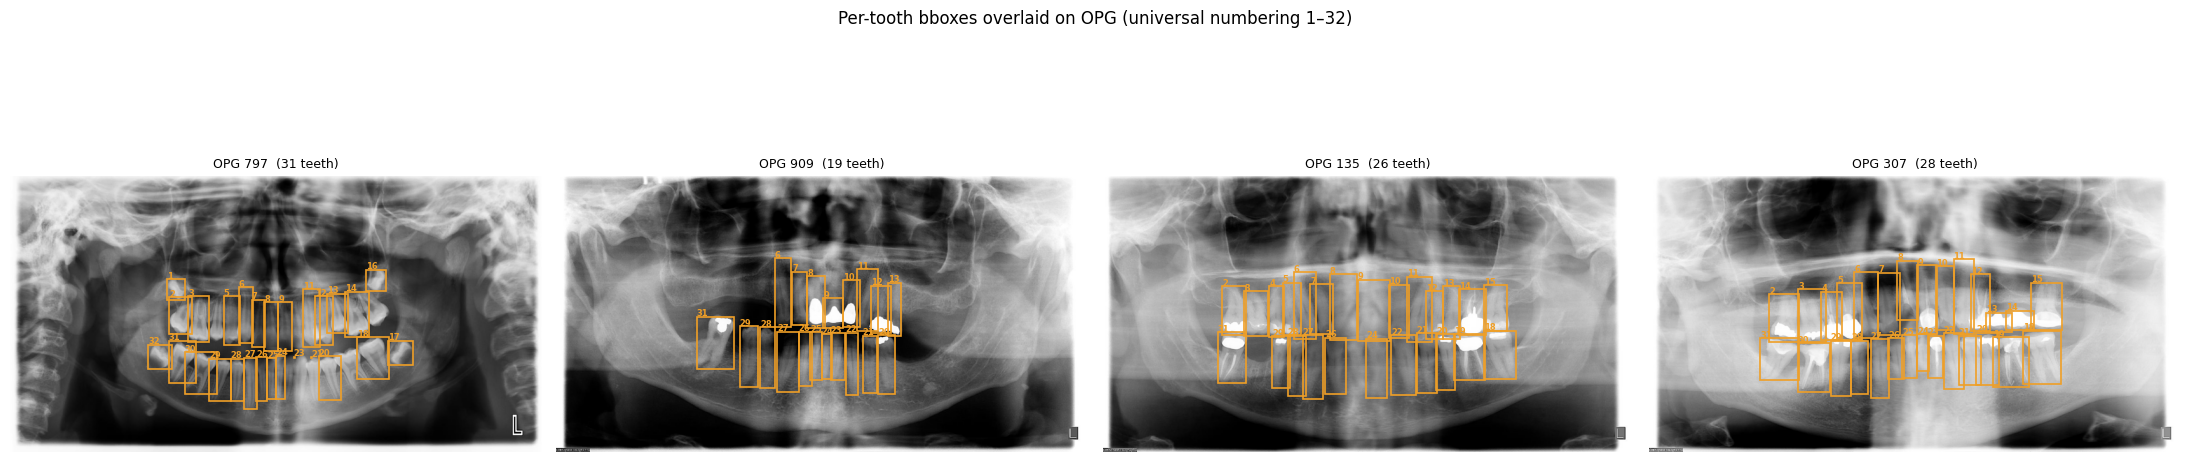

✅ Saved: bbox_overlay_fixed.png

Valid bbox records (w>5, h>5): 25903
  Width  : 7–185 px  (mean 63)
  Height : 13–350 px  (mean 145)


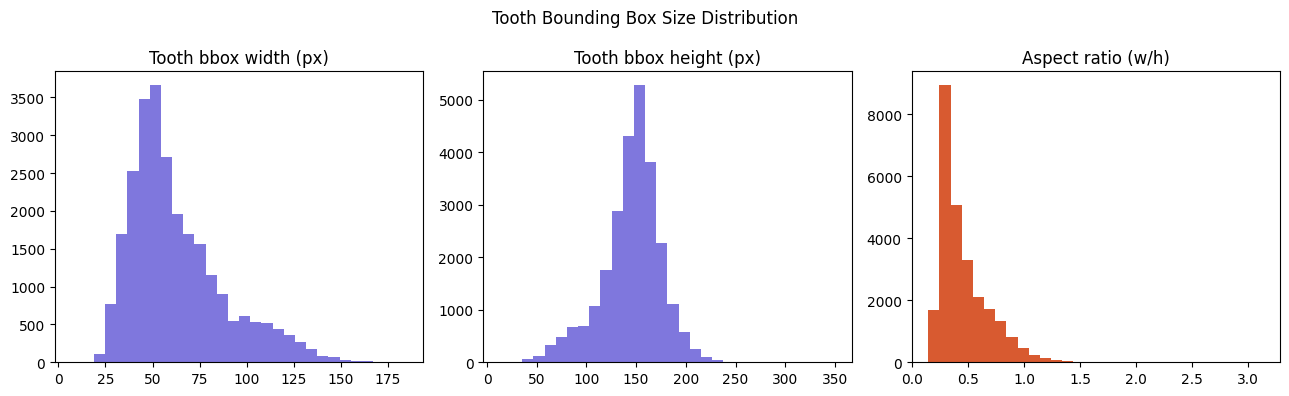

✅ Saved: bbox_stats_fixed.png


In [ ]:
# ── FINAL DIAGNOSTIC: Fix ID join + understand full picture ─

import json, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from PIL import Image as PILImage
PILImage.MAX_IMAGE_PIXELS = None

# ── 1. Parse expert.json correctly ────────────────────────
with open(EXPERT_JSON) as f:
    expert_raw = json.load(f)

expert_records = []
for item in expert_raw:
    ext_id      = item.get('External ID', '')
    description = item.get('Description', '')
    stem        = Path(ext_id).stem          # "53.JPG" → "53"
    objects     = item.get('Label', {}).get('objects', [])
    has_finding = not (len(objects) == 1 and
                       objects[0].get('title','').lower() == 'none')
    expert_records.append({
        'stem'       : stem,
        'ext_id'     : ext_id,
        'description': description,
        'has_finding': has_finding,
        'n_objects'  : len(objects),
    })

df_expert = pd.DataFrame(expert_records)
print(f"Expert records parsed: {len(df_expert)}")
print(f"Has finding          : {df_expert['has_finding'].sum()}")
print(f"Normal (no finding)  : {(~df_expert['has_finding']).sum()}")
print(f"\nSample records:")
print(df_expert.head(5).to_string())

# ── 2. Parse bbox.json correctly ──────────────────────────
with open(BBOX_JSON) as f:
    bbox_raw = json.load(f)

# IMPORTANT: bbox format is [y1, x1, y2, x2] corner points
# Convert → x, y, w, h
bbox_records = []
for item in bbox_raw:
    ext_id = item.get('External ID', '')
    stem   = Path(ext_id).stem
    for obj in item.get('Label', {}).get('objects', []):
        title = obj.get('title', '')
        bb    = obj.get('bounding box', [])
        if len(bb) == 4:
            y1, x1, y2, x2 = bb
            bbox_records.append({
                'stem'    : stem,
                'tooth_id': title,          # universal number string "1"–"32"
                'x'       : x1,
                'y'       : y1,
                'w'       : x2 - x1,
                'h'       : y2 - y1,
                'x1'      : x1, 'y1': y1,
                'x2'      : x2, 'y2': y2,
            })

df_bbox = pd.DataFrame(bbox_records)
print(f"\nBbox records parsed: {len(df_bbox)}")
print(f"Unique images      : {df_bbox['stem'].nunique()}")
print(f"Avg teeth / image  : {len(df_bbox)/df_bbox['stem'].nunique():.1f}")
print(f"Tooth IDs present  : {sorted(df_bbox['tooth_id'].unique())}")
print(df_bbox.head(5).to_string())

# ── 3. Fix coverage matrix with correct join ───────────────
radio_set       = set(Path(f).stem for f in os.listdir(RADIO_DIR))
expert_set      = set(df_expert['stem'].astype(str))
bbox_set        = set(df_bbox['stem'].astype(str))
teeth_mask_set  = set(Path(f).stem for f in os.listdir(TEETH_DIR)
                      if Path(f).suffix.lower() in {'.jpg','.jpeg','.png'})
expert_mask_set = set(Path(f).stem for f in os.listdir(EXPERT_MASK)
                      if Path(f).suffix.lower() in {'.jpg','.jpeg','.png'})

print("\n" + "=" * 55)
print("  CORRECTED COVERAGE MATRIX")
print("=" * 55)
coverage_fixed = {
    'Radiographs'                    : len(radio_set),
    'Expert labels'                  : len(expert_set),
    'Bbox annotations'               : len(bbox_set),
    'Teeth masks'                    : len(teeth_mask_set),
    'Expert pathology masks'         : len(expert_mask_set),
    'Radio ∩ Expert'                 : len(radio_set & expert_set),
    'Radio ∩ Bbox'                   : len(radio_set & bbox_set),
    'Radio ∩ Teeth mask'             : len(radio_set & teeth_mask_set),
    'Radio ∩ Expert mask'            : len(radio_set & expert_mask_set),
    'Radio ∩ Bbox ∩ Expert'          : len(radio_set & bbox_set & expert_set),
    'Radio ∩ Bbox ∩ Expert mask'     : len(radio_set & bbox_set
                                           & expert_mask_set),
    'FULL: Radio+Bbox+Expert+ExpMask': len(radio_set & bbox_set
                                           & expert_set & expert_mask_set),
}
for k, v in coverage_fixed.items():
    bar = '█' * int(v / 1000 * 35)
    print(f"  {k:38s} {v:4d}  {bar}")

# ── 4. Expert mask pixel value deep audit ─────────────────
expert_mask_files = sorted([
    os.path.join(EXPERT_MASK, f)
    for f in os.listdir(EXPERT_MASK)
    if Path(f).suffix.lower() in {'.jpg','.jpeg','.png'}
])

# Check: are empty masks truly empty (all 0)?
empty_count    = 0
nonempty_count = 0
val_distribution = []

for p in expert_mask_files[:100]:
    m    = np.array(PILImage.open(p).convert('L'))
    vals = np.unique(m)
    if set(vals) == {0}:
        empty_count += 1
    else:
        nonempty_count += 1
        val_distribution.extend(vals[vals > 0].tolist())

print(f"\nExpert mask audit (first 100):")
print(f"  Fully empty (all 0)  : {empty_count}")
print(f"  Has annotation       : {nonempty_count}")
print(f"  Non-zero pixel values seen: {sorted(set(val_distribution))[:40]}")

# ── 5. Join: for each image with expert mask,
#        find its diagnosis description ────────────────────
df_expert_idx = df_expert.set_index('stem')
joined_rows   = []

for p in expert_mask_files:
    stem = Path(p).stem
    m    = np.array(PILImage.open(p).convert('L'))
    is_empty = (m.max() == 0)
    desc = ''
    if stem in df_expert_idx.index:
        desc = df_expert_idx.loc[stem, 'description']
        if isinstance(desc, pd.Series):
            desc = desc.iloc[0]
    joined_rows.append({
        'stem'         : stem,
        'mask_empty'   : is_empty,
        'has_bbox'     : stem in bbox_set,
        'description'  : str(desc)[:80],
    })

df_joined = pd.DataFrame(joined_rows)
print(f"\nJoined expert mask + description:")
print(f"  Total expert mask images : {len(df_joined)}")
print(f"  Mask empty (normal)      : {df_joined['mask_empty'].sum()}")
print(f"  Mask has annotation      : {(~df_joined['mask_empty']).sum()}")
print(f"  Also has bbox            : {df_joined['has_bbox'].sum()}")
print(f"\nSample joined records:")
print(df_joined[~df_joined['mask_empty']].head(8).to_string())

# ── 6. Bbox overlay on real OPG with correct parsing ──────
sample_stems = df_bbox['stem'].unique()[:4]
fig, axes    = plt.subplots(1, 4, figsize=(22, 6))

for ax, stem in zip(axes, sample_stems):
    rp = None
    for ext in ['.JPG','.jpg','.jpeg','.png']:
        cand = os.path.join(RADIO_DIR, stem + ext)
        if os.path.exists(cand): rp = cand; break

    if rp is None:
        ax.text(0.5, 0.5, 'No OPG', ha='center',
                transform=ax.transAxes)
        ax.axis('off')
        continue

    radio = np.array(PILImage.open(rp).convert('RGB'))
    ax.imshow(radio, cmap='gray')

    teeth = df_bbox[df_bbox['stem'] == stem]
    for _, row in teeth.iterrows():
        if row['w'] < 3 or row['h'] < 3:
            continue   # skip degenerate bboxes
        rect = mpatches.Rectangle(
            (row['x'], row['y']), row['w'], row['h'],
            linewidth=1.2, edgecolor='#EF9F27', facecolor='none')
        ax.add_patch(rect)
        ax.text(row['x'], row['y'] - 3, str(row['tooth_id']),
                color='#EF9F27', fontsize=6, fontweight='bold')

    ax.set_title(f"OPG {stem}  ({len(teeth)} teeth)", fontsize=9)
    ax.axis('off')

plt.suptitle("Per-tooth bboxes overlaid on OPG (universal numbering 1–32)",
             fontsize=12)
plt.tight_layout()
plt.savefig('/content/bbox_overlay_fixed.png', dpi=130, bbox_inches='tight')
plt.show()
print("✅ Saved: bbox_overlay_fixed.png")

# ── 7. Tooth size statistics (valid bboxes only) ──────────
valid = df_bbox[(df_bbox['w'] > 5) & (df_bbox['h'] > 5)].copy()
print(f"\nValid bbox records (w>5, h>5): {len(valid)}")
print(f"  Width  : {valid['w'].min():.0f}–{valid['w'].max():.0f} px"
      f"  (mean {valid['w'].mean():.0f})")
print(f"  Height : {valid['h'].min():.0f}–{valid['h'].max():.0f} px"
      f"  (mean {valid['h'].mean():.0f})")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].hist(valid['w'], bins=30, color='#7F77DD')
axes[0].set_title("Tooth bbox width (px)")
axes[1].hist(valid['h'], bins=30, color='#7F77DD')
axes[1].set_title("Tooth bbox height (px)")
axes[2].hist(valid['w']/valid['h'], bins=30, color='#D85A30')
axes[2].set_title("Aspect ratio (w/h)")
plt.suptitle("Tooth Bounding Box Size Distribution", fontsize=12)
plt.tight_layout()
plt.savefig('/content/bbox_stats_fixed.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved: bbox_stats_fixed.png")